(Tutorial_Get_atom_correspondences)=
# Getting atom correspondences

*Finding reusable chemical bijections with original source indices.*

Compare declared chemical graphs independently of coordinates. The experimental `declared_graph_isomorphism` profile recognizes symmetries while preserving formal charge, isotope labels, bonds, aromaticity, H inventory and assigned stereo. Select atoms from one complete covalent component. Its unselected atoms remain chemical context.

:::{admonition} API documentation
:class: dropdown
{func}`molsysmt.chemical_states.get_atom_correspondences`
:::

:::{versionadded} 1.0.0
:::

## Inspecting complete maps

This benzene control has six rotations and six reflections. Each two-column map contains query and reference **source indices**, distinct from IDs. RDKit is an explicit optional execution dependency.
Use plain integer atom/structure indices. Physical quantities and explicit
dimensionless quantity wrappers are rejected before calculation; units do not
turn a molecular length into a positional index.


In [1]:
import molsysmt as msm
import numpy as np
from rdkit import Chem

molsys = Chem.MolFromSmiles('c1ccccc1')
result = msm.chemical_states.get_atom_correspondences(molsys)
assert result['atom_correspondences'].shape == (12, 6, 2)
print(result['atom_correspondences'][0])

[[0 0]
 [1 1]
 [2 2]
 [3 3]
 [4 4]
 [5 5]]


## Preserving chemical context

A metric may omit H, but the complete graph still distinguishes sites. Benzamidinium declared as `NC(=[NH2+])c1ccccc1` permits two phenyl mappings. The single-bond N and double-bond/+1 N remain distinct. No resonance or protonation normalization occurs.

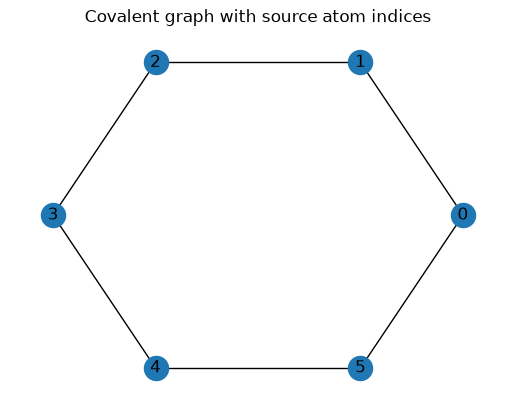

In [2]:
import networkx as nx
import matplotlib.pyplot as plt
molsys_graph = msm.convert(molsys, to_form='networkx.Graph')
fig, ax = plt.subplots()
nx.draw_networkx(molsys_graph, pos=nx.circular_layout(molsys_graph), ax=ax)
ax.set_title('Covalent graph with source atom indices')
ax.set_axis_off()
plt.show()

In [3]:
molsys = Chem.MolFromSmiles('NC(=[NH2+])c1ccccc1')
result = msm.chemical_states.get_atom_correspondences(molsys)
assert result['atom_correspondences'].shape == (2, 9, 2)
assert np.all(result['atom_correspondences'][:, 0, 1] == 0)
assert np.all(result['atom_correspondences'][:, 2, 1] == 2)
subset = msm.chemical_states.get_atom_correspondences(molsys, selection=[4, 8])
print(subset['selection_atom_indices'])
print(subset['context_atom_correspondences'].shape)

[4 8]
(2, 9, 2)


## Comparing reordered sources

The reference can have a different atom order. Maps retain that independent order. Atom selection itself is sorted and does not encode a permutation.

In [4]:
molsys_A = Chem.MolFromSmiles('CCO')
molsys_B = Chem.RenumberAtoms(molsys_A, [2, 0, 1])
result = msm.chemical_states.get_atom_correspondences(molsys_A, reference_molecular_system=molsys_B)
assert result['atom_correspondences'].tolist() == [[[0, 1], [1, 2], [2, 0]]]
print(result['atom_correspondences'])

[[[0 1]
  [1 2]
  [2 0]]]


## Anchoring atoms and supplying complete maps

`fixed_atom_correspondence` contains partial query/reference source-index pairs. Each endpoint is unique. Anchors can belong to the complete chemical component even when those atoms are absent from the selected metric population. They prune RDKit's compiled search before the candidate cap; they do not change elements, isotope labels or stereo.

`candidate_atom_correspondences` supplies one complete selected-population map `(n_selected, 2)` or a collection `(n_maps, n_selected, 2)`. Every proposed map must extend to the full chemical context and respect all anchors. An invalid candidate raises instead of being silently discarded. Row order does not determine correspondence: each row explicitly names both source indices. Duplicates are removed and admitted maps have canonical order.


In [5]:
molsys = Chem.MolFromSmiles('c1ccccc1')
anchored = msm.chemical_states.get_atom_correspondences(
    molsys, fixed_atom_correspondence=[[0, 0]], max_matches=2)
assert anchored['atom_correspondences'].shape == (2, 6, 2)
assert anchored['n_candidate_matches'] == 2
identity_map = np.column_stack((np.arange(6), np.arange(6)))
proposed = msm.chemical_states.get_atom_correspondences(
    molsys, candidate_atom_correspondences=identity_map)
assert proposed['atom_correspondences'].shape == (1, 6, 2)
print(anchored['search_scope'])
print(proposed['search_scope'])


anchored_chemical_correspondences
supplied_atom_correspondences


`search_complete=True` refers to `search_scope`: `all_chemical_correspondences`, `anchored_chemical_correspondences` or `supplied_atom_correspondences`. A supplied subset never certifies the unrestricted symmetry minimum. The result stores detached anchors and canonical candidates in its consistency digest. Reuse preserves their scope; supply the cached dictionary alone, rather than adding new constraints during geometry evaluation.

For candidate admission only one full-context extension is needed. Bounded existence searches select a lexical witness without collecting all omitted-H permutations. This bypasses full symmetry enumeration, but still validates chemistry and requires RDKit.


## Choosing states and limits

`chemical_state` and `reference_chemical_state` choose states independently. `'structure'` requires one fixed state across the requested structures. `structure_indices` and `reference_structure_indices` serve state/selection resolution; coordinates do not establish chemical equivalence.

Required context metadata includes elements, formal charge, aromaticity, radical count, stored implicit/explicit H counts and H policy, supported bond orders, and atom stereo declarations. Potential stereochemistry must be assigned. A legacy dictionary or PDB with insufficient assignments raises; missing evidence is not inferred. Dative, enhanced and other unsupported stereo, different resonance representations and disconnected metric populations are outside this profile.

`max_matches` bounds full-context candidates **before** exact filtering or selected-population deduplication. Exceeding that bound or the RAM estimate raises without returning a truncated result. The bound is not a time limit. Empty matches have shape `(0, n_selected, 2)`; an empty metric population is invalid.

## Understanding attribution

The method is inspired by [Bell and Zhang (2019)](https://doi.org/10.1186/s13321-019-0362-7) and [Meli and Biggin (2020)](https://doi.org/10.1186/s13321-020-00455-2). It does not reproduce DockRMSD or sPyRMSD faithfully. RDKit executes graph matching; MolSysMT applies its own declared-state constraints. `references`, `software` and detached `attribution` retain those distinctions. Optional Ackredit credits methodological inspiration separately from executed software in your current session.

When assigned stereo labels are used, RDKit executes the [Hanson et al. (2018) CIP algorithm](https://doi.org/10.1021/acs.jcim.8b00324). This reused scientific criterion is recorded separately from the inspiration for pose RMSD.

Both graphs require the same indexed-H representation and stored H policy. Materializing H or converting explicit/implicit H encodings belongs to separate chemical preparation. For already declared aromatic bonds in a Kekule representation, {func}`molsysmt.physchem.normalize_aromatic_bond_orders` can explicitly normalize bond-order representation before matching.


In [6]:
print([(item['title'], item['roles']) for item in result['attribution']['items']])

[('DockRMSD: an open-source tool for atom mapping and RMSD calculation of symmetric molecules through graph isomorphism', ['methodological_inspiration']), ('spyrmsd: symmetry-corrected RMSD calculations in Python', ['methodological_inspiration']), ('MolSysMT', ['executed_software']), ('RDKit: Open-source cheminformatics', ['executed_software'])]


:::{seealso}
:class: dropdown
{ref}`Tutorial_Get_symmetry_corrected_rmsd` evaluates these maps without superposition. {func}`molsysmt.physchem.get_cip_stereochemistry` handles explicit general stereo analysis. {ref}`Cookbook_SymmetryPoseRMSD` preserves an original baseline alongside the corrected result.
:::